# Лабораторна робота №5. Кластеризація
Горбач Ангеліна, ФІ-31


Дані — [Vehicle Dataset from CarDekho](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import config_context
from sklearn.cluster import AgglomerativeClustering, Birch
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.preprocessing import StandardScaler

## 1. Аналіз і підготовка даних

In [2]:
raw = pd.read_csv("Car details v3.csv")
print(f"Рядків: {len(raw)}, стовпців: {raw.shape[1]}")
print(f"Повних дублікатів: {raw.duplicated().sum()}")

cars = raw.drop_duplicates().copy()
cars["engine_cc"] = cars["engine"].str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
cars["power_bhp"] = cars["max_power"].str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)

features = ["year", "km_driven", "engine_cc", "power_bhp"]
names = ["Рік випуску", "Пробіг, км", "Об’єм, см³", "Потужність, bhp"]
print("\nПропуски в обраних ознаках")
print(cars[features].isna().sum().rename(index=dict(zip(features, names))))

Рядків: 8128, стовпців: 13
Повних дублікатів: 1202

Пропуски в обраних ознаках
Рік випуску          0
Пробіг, км           0
Об’єм, см³         208
Потужність, bhp    206
dtype: int64


Записів із пропусками: 209
Записів із недодатними значеннями: 0
Записів із пробігом понад 1 млн км: 2
Авто для кластеризації: 6715

Потенційні викиди за правилом 1,5 IQR
Рік випуску          56
Пробіг, км          159
Об’єм, см³         1206
Потужність, bhp     304
dtype: int64
Кореляція об’єму двигуна й потужності: 0.683


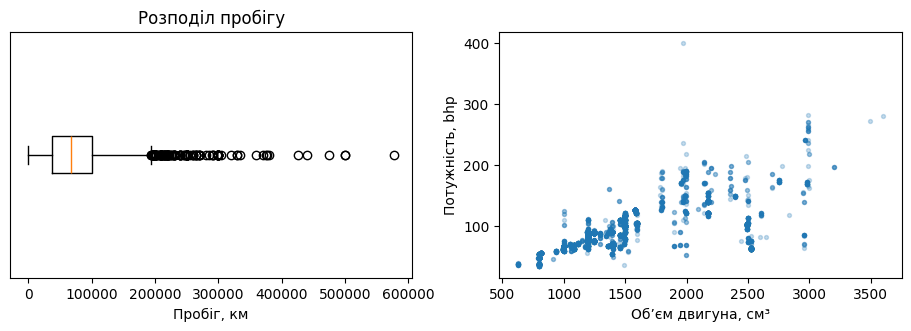

In [3]:
complete = cars.dropna(subset=features)
invalid = (complete[["km_driven", "engine_cc", "power_bhp"]] <= 0).any(axis=1)
extreme_km = complete["km_driven"] > 1_000_000
cars = complete.loc[~(invalid | extreme_km)].copy()
print(f"Записів із пропусками: {len(raw.drop_duplicates()) - len(complete)}")
print(f"Записів із недодатними значеннями: {invalid.sum()}")
print(f"Записів із пробігом понад 1 млн км: {extreme_km.sum()}")
print(f"Авто для кластеризації: {len(cars)}")

values = cars[features]
q1 = values.quantile(0.25)
q3 = values.quantile(0.75)
iqr = q3 - q1
outliers = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
print("\nПотенційні викиди за правилом 1,5 IQR")
print(outliers.sum().rename(index=dict(zip(features, names))))
print(f"Кореляція об’єму двигуна й потужності: {values['engine_cc'].corr(values['power_bhp']):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
axes[0].boxplot(values["km_driven"], vert=False)
axes[0].set(xlabel="Пробіг, км", title="Розподіл пробігу", yticks=[])
axes[1].scatter(values["engine_cc"], values["power_bhp"], s=8, alpha=0.25)
axes[1].set(xlabel="Об’єм двигуна, см³", ylabel="Потужність, bhp")
plt.show()

X = StandardScaler().fit_transform(values)

Записи з пропусками в обраних ознаках видаляю. Як і в попередніх роботах, прибираю записи з пробігом понад 1 млн км. Решту нетипових значень відмічаю за правилом IQR і залишаю в даних. Масштабую ознаки перед розрахунком відстаней.

## 2. Власний K-means
Для початкових центрів використовую k-means++. Потім відношу кожне авто до найближчого центру й перераховую центри як середні значення ознак у групах. Із кількох запусків беру той, у якого найменша інерція.

In [4]:
def squared_distances(X, centers):
    return ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)


def initial_centers(X, k, rng):
    centers = [X[rng.integers(len(X))]]
    closest = ((X - centers[0]) ** 2).sum(axis=1)
    for _ in range(1, k):
        index = rng.choice(len(X), p=closest / closest.sum())
        centers.append(X[index])
        closest = np.minimum(closest, ((X - X[index]) ** 2).sum(axis=1))
    return np.array(centers)


def kmeans(X, k, n_init=8, max_iter=300, seed=42):
    rng = np.random.default_rng(seed)
    best_inertia = np.inf

    for _ in range(n_init):
        centers = initial_centers(X, k, rng)
        previous_labels = None

        for _ in range(max_iter):
            distances = squared_distances(X, centers)
            labels = distances.argmin(axis=1)
            counts = np.bincount(labels, minlength=k)

            # Move a distant point to each empty cluster.
            nearest = distances[np.arange(len(X)), labels]
            for empty in np.flatnonzero(counts == 0):
                candidates = np.flatnonzero(counts[labels] > 1)
                point = candidates[nearest[candidates].argmax()]
                counts[labels[point]] -= 1
                labels[point] = empty
                counts[empty] += 1

            centers = np.array([X[labels == group].mean(axis=0) for group in range(k)])
            if np.array_equal(labels, previous_labels):
                break
            previous_labels = labels.copy()
        else:
            continue

        inertia = ((X - centers[labels]) ** 2).sum()
        if inertia < best_inertia:
            best_inertia = inertia
            best_labels = labels.copy()
            best_centers = centers.copy()

    if not np.isfinite(best_inertia):
        raise RuntimeError("Кластери не стабілізувалися. Треба збільшити max_iter.")
    return best_labels, best_centers, best_inertia

## 3. Вибір кількості кластерів
Перевіряю від 2 до 8 кластерів. На графіку інерції шукаю місце, після якого вона зменшується повільніше. Кількість кластерів обираю за найбільшим silhouette score. Для всіх варіантів рахую його на всій підготовленій вибірці.

      Інерція  Silhouette  Найменша група
k                                        
2  18733.7752      0.3983            1530
3  13862.6523      0.3190            1329
4  11892.9929      0.3212             664
5  10368.6701      0.3009             612
6   9353.1717      0.2880             253
7   8462.2156      0.2612             170
8   7789.8705      0.2674             163
Обрана кількість кластерів: 2


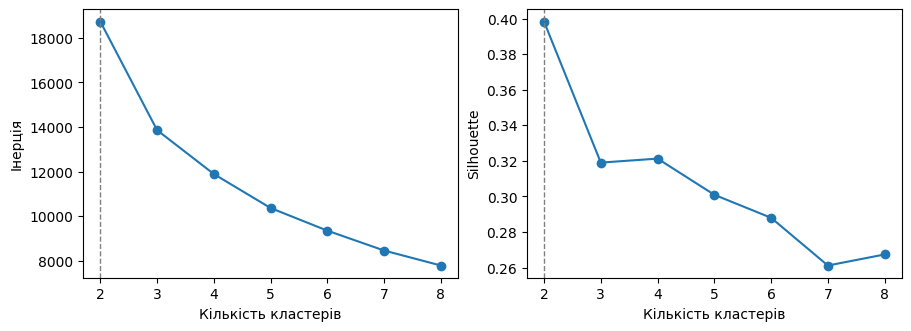

In [5]:
def silhouette(labels):
    with config_context(working_memory=64):
        return silhouette_score(X, labels)

solutions = {}
rows = []
for k in range(2, 9):
    labels, centers, inertia = kmeans(X, k)
    solutions[k] = (labels, centers, inertia)
    rows.append((k, inertia, silhouette(labels), np.bincount(labels).min()))

scores = pd.DataFrame(rows, columns=["k", "Інерція", "Silhouette", "Найменша група"]).set_index("k")
best_k = int(scores["Silhouette"].idxmax())
print(scores.round(4).to_string())
print(f"Обрана кількість кластерів: {best_k}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), layout="constrained")
for ax, metric in zip(axes, ["Інерція", "Silhouette"]):
    ax.plot(scores.index, scores[metric], marker="o")
    ax.axvline(best_k, color="gray", linestyle="--", linewidth=1)
    ax.set(xlabel="Кількість кластерів", ylabel=metric, xticks=scores.index)
plt.show()

## 4. Порівняння методів
Для порівняння запускаю агломеративну кластеризацію з методом Варда та BIRCH. Використовую ті самі ознаки й кількість кластерів. Calinski–Harabasz і розміри груп рахую на всіх авто.

                 Кластерів  Silhouette  Calinski–Harabasz Розміри груп
Метод                                                                 
K-means (NumPy)          2      0.3983          2911.9249   5185, 1530
Agglomerative            2      0.4183          2644.3419   5525, 1190
BIRCH                    2      0.3820          1957.6625    5915, 800


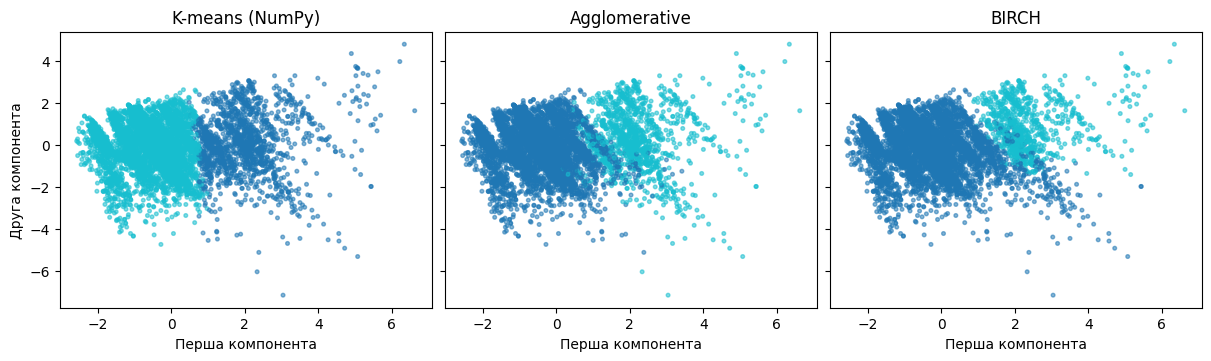

In [6]:
groups = {
    "K-means (NumPy)": solutions[best_k][0],
    "Agglomerative": AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit_predict(X),
    "BIRCH": Birch(n_clusters=best_k, threshold=0.5).fit_predict(X),
}

comparison = []
for method, labels in groups.items():
    sizes = np.unique(labels, return_counts=True)[1]
    comparison.append((method, len(sizes), silhouette(labels),
                       calinski_harabasz_score(X, labels), ", ".join(map(str, sorted(sizes, reverse=True)))))

comparison = pd.DataFrame(comparison, columns=["Метод", "Кластерів", "Silhouette",
                                                "Calinski–Harabasz", "Розміри груп"]).set_index("Метод")
print(comparison.round(4).to_string())

points = PCA(n_components=2).fit_transform(X)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharex=True, sharey=True, layout="constrained")
for ax, (method, labels) in zip(axes, groups.items()):
    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap="tab10", s=7, alpha=0.55)
    ax.set(title=method, xlabel="Перша компонента")
axes[0].set_ylabel("Друга компонента")
plt.show()

## 5. Опис груп K-means
Порівнюю медіани, щоб описати типове авто в кожній групі. Графік вище показує двовимірну проєкцію PCA. Моделі навчалися на чотирьох ознаках.

In [7]:
cars["cluster"] = groups["K-means (NumPy)"] + 1
profile = cars.groupby("cluster").agg(
    count=("year", "size"), year=("year", "median"), km=("km_driven", "median"),
    displacement=("engine_cc", "median"), power=("power_bhp", "median"),
    price=("selling_price", "median"),
).sort_values("year")
profile.columns = ["Кількість", *names, "Ціна"]
profile.index.name = "Кластер"
print(profile.round(1).to_string())

         Кількість  Рік випуску  Пробіг, км  Об’єм, см³  Потужність, bhp      Ціна
Кластер                                                                           
1             1530       2013.0     95000.0      2179.0            120.0  600000.0
2             5185       2015.0     60000.0      1199.0             74.0  375000.0


## Висновок

Я перевірила, як K-means розподіляє автомобілі на групи, і обрала два кластери. Для цього поділу silhouette був найвищим серед перевірених варіантів — 0,3983. При трьох кластерах інерція зменшилася, а silhouette знизився до 0,3190.

У першому кластері 1530 авто, у другому — 5185. Медіанний рік випуску в першій групі — 2013, у другій — 2015. У першій групі також вищі медіанний пробіг (95 тис. км проти 60 тис. км) і потужність (120 bhp проти 74 bhp). Ціну я порівняла вже після кластеризації. У першій групі медіанна ціна становила 600 000, а в другій — 375 000.

Серед трьох методів найвищий silhouette отримала для методу Варда (0,4183), а найвищий індекс Calinski–Harabasz — для K-means (2911,92). У BIRCH обидва показники були нижчими, ніж у двох інших методів.
